# ColorMNIST Paper Figures: Colour Deconfounding Along the Flow, Both Arms

Produces the qualitative figures for the ColorMNIST experiment at the simulation's
full scale ($n_{\mathrm{obs}} = 20000$, reference recolouring parameters, disjoint
autoencoder split), following the simulation script's exact seed path
(`data_seed = 0`, `repeat = 0`) — this run is the same run, up to CUDA
nondeterminism, as the corresponding rows of
`Simulations/ColorMNIST/dr_mmd_flow/results/`.

Two figures per arm: **decoded particle trajectories** along the IMQ MMD flow
(selected particles $\times$ iterations), and the **colour-ratio law** $R/(R+B)$ of
the initial, flowed and oracle samples. Workflow as in the CelebA sibling: run,
eyeball the candidate grids in Section 4, put chosen indices into the `TRACK` lists
in Section 5, re-run that cell — PDFs land in `figures/`. Particle indices are
specific to `(N_OBS, seed)`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import IMQKernel, RBF, imq_c_from_median
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import mmd_gradient_flow

SEED = 0          # = the simulation's pipeline seed for (data_seed 0, repeat 0)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [2]:
N_OBS = 20000
W_CONF, TAU, ALPHA, K_MASK = 10.0, 0.08, 0.0, 10.0
M, N_DR = 1600, 4000

pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(0)          # data_seed = 0
X_obs, A_obs, Y_obs = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU,
                                      alpha=ALPHA, k_mask=K_MASK, generator=generator)
data = to_model_range(Y_obs)

n_ae = N_OBS // 2
split = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(SEED + 2),
                       device=device)
ae_idx, causal_idx = split[:n_ae], split[n_ae:]

ae, _ = train_conv_ae(data[ae_idx], latent_dim=32, n_iterations=3000, batch_size=128,
                      learning_rate=1e-3, device=device,
                      generator=torch.Generator(device=device).manual_seed(SEED),
                      log_every=1500, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)
print(f"n = {N_OBS}   AE split {n_ae} / causal {len(causal_idx)}")

n = 20000   AE split 10000 / causal 10000


In [3]:
# Cross-fitted DR weights and per-arm flows, mirroring the simulation line for line.
pick_dr = torch.randperm(len(causal_idx),
                         generator=torch.Generator(device=device).manual_seed(SEED + 5),
                         device=device)[:N_DR]
subsample = causal_idx[pick_dr]
X_s, A_s = X_obs[subsample], A_obs[subsample]
Z_s = encode_in_batches(ae.encode, data[subsample])

fold_ids = make_crossfit_fold_ids(N_DR, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)

kernel_x = RBF(use_length_scale_heuristic=True)
K_x = kernel_x(X_s.unsqueeze(1).double().cpu())
K_a = (A_s[:, None] == A_s[None, :]).double().cpu()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_s[train, 0].double().cpu(), seed=0)

c_imq = imq_c_from_median(Z_s)
kernel = IMQKernel(c=c_imq, beta=-0.5)
step_size = 0.15 * c_imq ** 2

flows = {}
for arm in (0, 1):
    e_target = e1 if arm == 1 else 1.0 - e1
    w_hat = (A_s.cpu() == arm).double() / e_target
    K_a_target = (A_s == arm).double().cpu()[:, None].expand(N_DR, N_DR).contiguous()
    v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                    fold_lambdas).float().to(device)

    arm_causal = causal_idx[A_obs[causal_idx] == arm]
    Z_arm = encode_in_batches(ae.encode, data[arm_causal])
    pick = torch.randperm(Z_arm.shape[0],
                          generator=torch.Generator(device=device).manual_seed(SEED + 1),
                          device=device)[:M]
    initial = Z_arm[pick].clone()
    particles, history = mmd_gradient_flow(kernel, target_samples=Z_s,
                                           initial_particles=initial,
                                           step_size=step_size, n_iterations=3000,
                                           target_weights=v_dr, snapshot_every=250,
                                           log_every=1000, verbose=False)
    flows[arm] = {"initial": initial, "particles": particles,
                  "snapshots": dict(sorted(history["snapshots"].items()))}
    flows[arm]["snapshots"][3000] = particles
    print(f"arm {arm}: M = {len(initial)}   objective "
          f"{history['squared_mmd'][0]:.2e} -> {history['squared_mmd'][-1]:.2e}")

arm 0: M = 1600   objective 1.18e-03 -> 1.46e-05


arm 1: M = 1600   objective 1.36e-03 -> 3.06e-05


## 4. Candidate Selection

Start/end pairs per arm: top 24 particles by pixel change (indices above each pair),
then 24 random. Arm 0 recolours blue-ward digits toward the marginal, arm 1 red-ward
digits — good candidates show a clear colour move on an intact digit.

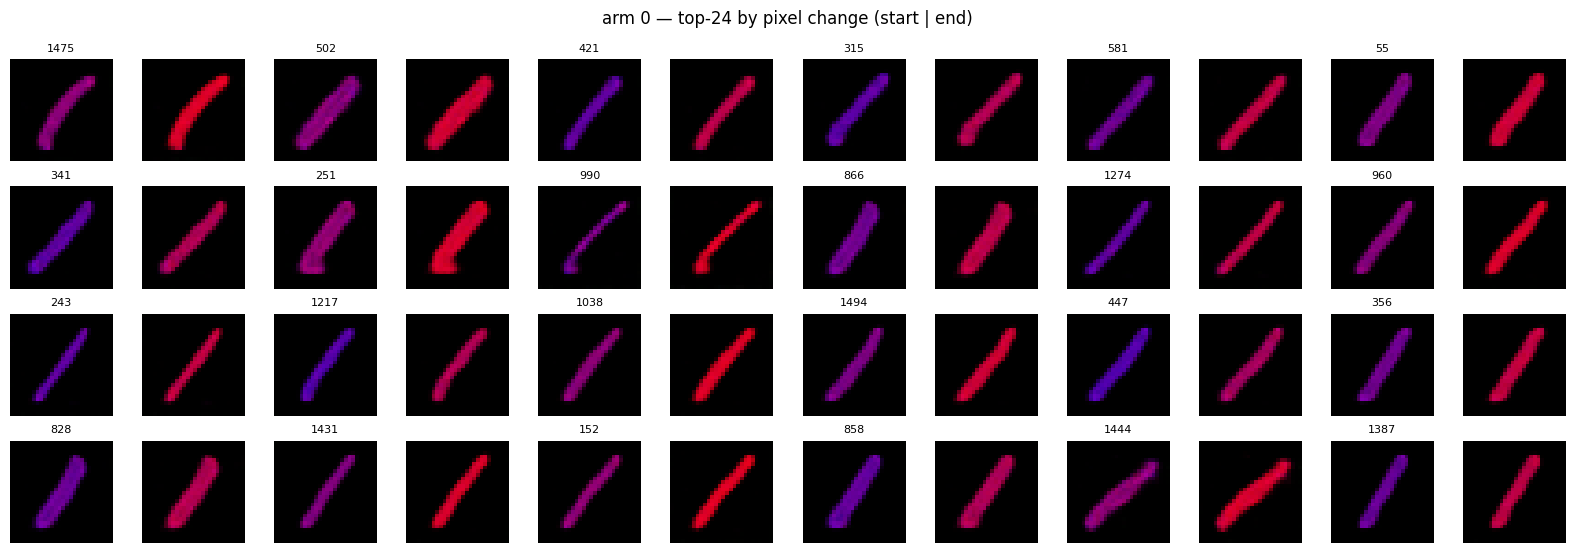

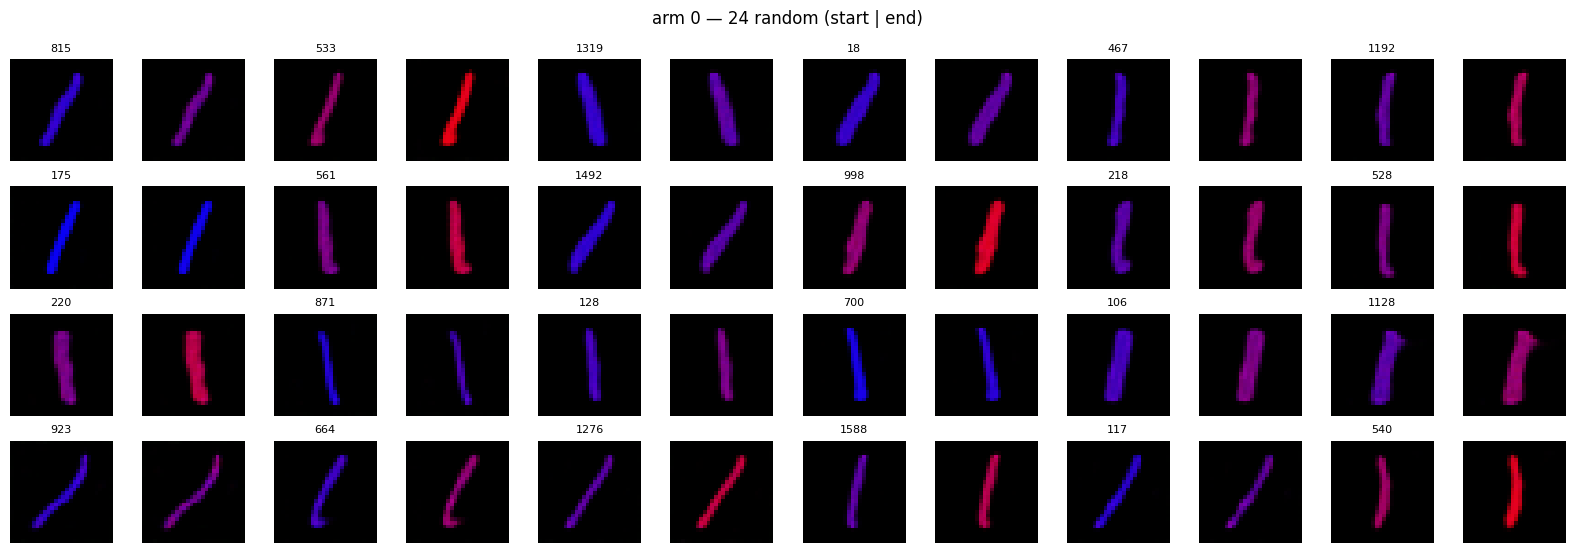

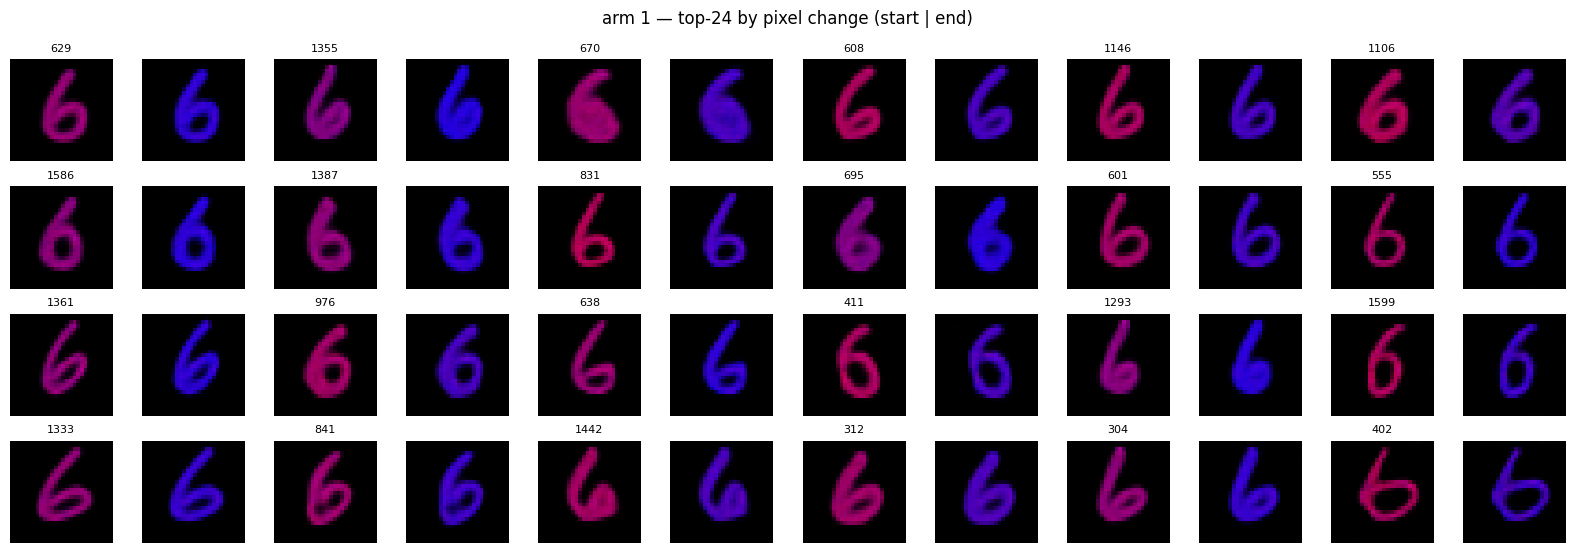

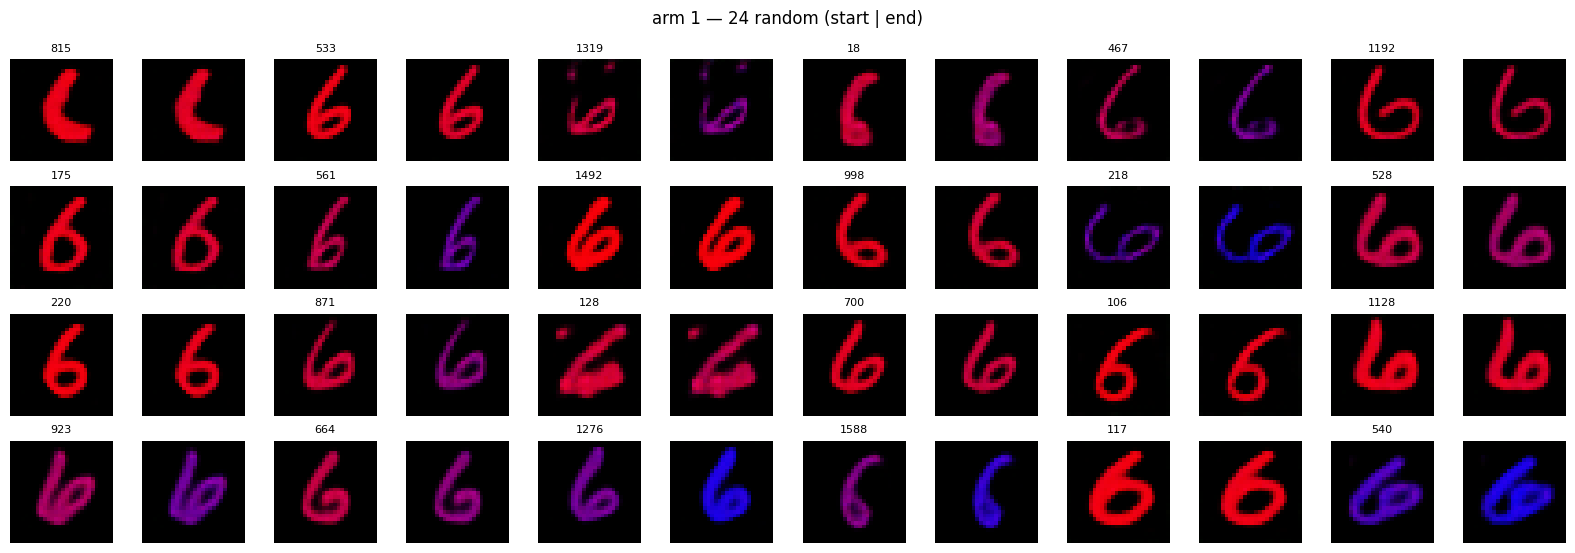

In [4]:
@torch.no_grad()
def decode_all(latents, chunk=512):
    return torch.cat([ae.decode(latents[i:i + chunk]).cpu()
                      for i in range(0, len(latents), chunk)])


decoded = {}
for arm in (0, 1):
    start = to_image_range(decode_all(flows[arm]["initial"]))
    end = to_image_range(decode_all(flows[arm]["particles"]))
    change = (end - start).flatten(1).norm(dim=1)
    decoded[arm] = {"start": start, "end": end, "change": change}

for arm in (0, 1):
    change = decoded[arm]["change"]
    top = torch.argsort(change, descending=True)[:24]
    rng = torch.randperm(len(change), generator=torch.Generator().manual_seed(7))[:24]
    for label, indices in (("top-24 by pixel change", top), ("24 random", rng)):
        fig, axes = plt.subplots(4, 12, figsize=(16, 5.6))
        for k, index in enumerate(indices):
            row, col = divmod(k, 6)
            for j, stage in enumerate(("start", "end")):
                ax = axes[row, 2 * col + j]
                ax.imshow(decoded[arm][stage][index].permute(1, 2, 0).clamp(0, 1).numpy())
                ax.axis("off")
                if j == 0:
                    ax.set_title(f"{int(index)}", fontsize=8)
        fig.suptitle(f"arm {arm} — {label} (start | end)", fontsize=12)
        fig.tight_layout()
        plt.show()

## 5. Paper Figure 1: Decoded Trajectories Along the Flow

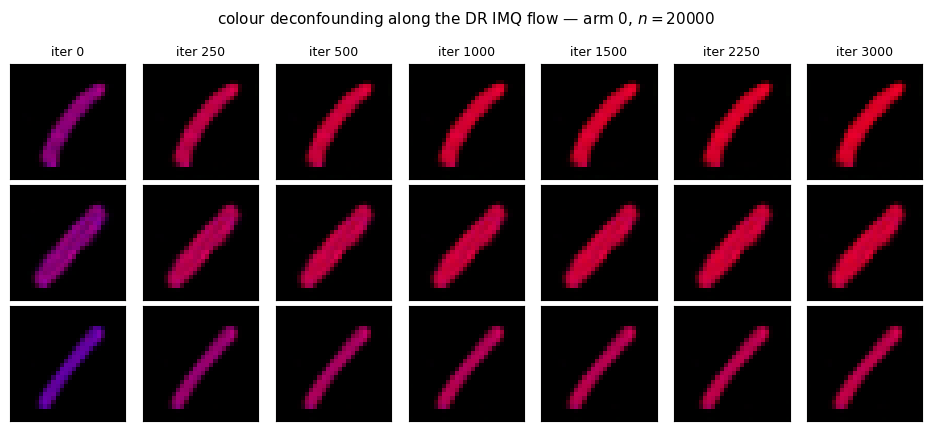

arm 0: tracked [1475, 502, 421] -> figures/colormnist_flow_arm0_n20000.pdf


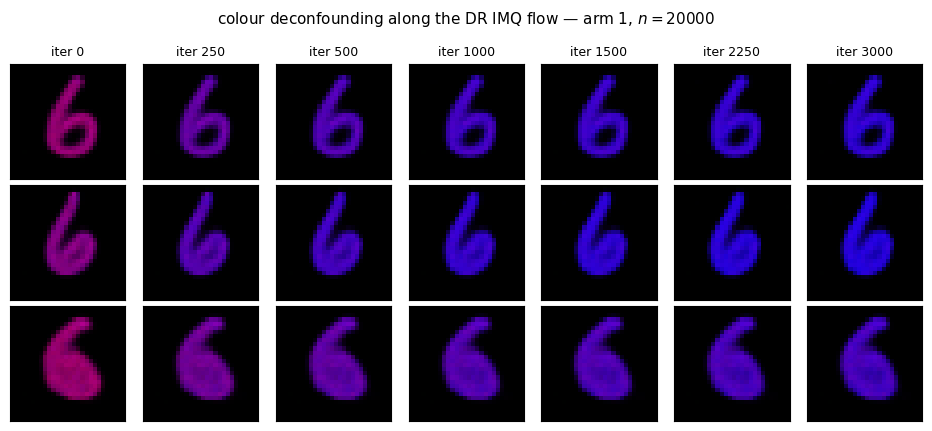

arm 1: tracked [629, 1355, 670] -> figures/colormnist_flow_arm1_n20000.pdf


In [5]:
TRACK = {0: None, 1: None}    # e.g. {0: [12, 847, 55], 1: [3, 91, 640]}; None -> top-3
SHOWN_STEPS = [0, 250, 500, 1000, 1500, 2250, 3000]
Path("figures").mkdir(exist_ok=True)

for arm in (0, 1):
    track = TRACK[arm]
    if track is None:
        track = torch.argsort(decoded[arm]["change"], descending=True)[:3].tolist()
    snapshots = flows[arm]["snapshots"]
    with torch.no_grad():
        frames = {step: to_image_range(ae.decode(snapshots[step][track]).cpu())
                  for step in SHOWN_STEPS}
    fig, axes = plt.subplots(len(track), len(SHOWN_STEPS),
                             figsize=(1.35 * len(SHOWN_STEPS), 1.45 * len(track)))
    for row, particle in enumerate(track):
        for col, step in enumerate(SHOWN_STEPS):
            axes[row, col].imshow(frames[step][row].permute(1, 2, 0).clamp(0, 1).numpy())
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(f"iter {step}", fontsize=9)
    fig.suptitle(f"colour deconfounding along the DR IMQ flow — arm {arm}, "
                 f"$n = {N_OBS}$", fontsize=11)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(f"figures/colormnist_flow_arm{arm}_n{N_OBS}.{ext}",
                    dpi=200, bbox_inches="tight")
    plt.show()
    print(f"arm {arm}: tracked {track} -> figures/colormnist_flow_arm{arm}_n{N_OBS}.pdf")

## 6. Paper Figure 2: the Colour-Ratio Law

Kernel density of $\mathrm{logit}\, R/(R+B)$: the observed arm, the flowed sample,
and an oracle interventional draw (seed-matched to the simulation's evaluation
draw), one panel per arm.

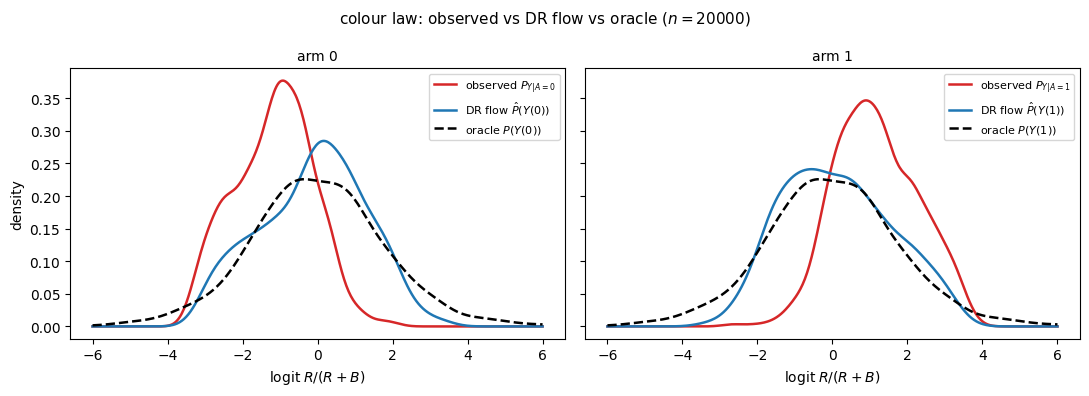

-> figures/colormnist_colour_law_n20000.pdf


In [6]:
grid = np.linspace(-6, 6, 400)
logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for arm, ax in zip((0, 1), axes):
    _, Y_oracle = sample_interventional(pools, len(flows[arm]["initial"]), a=arm,
                                        tau=TAU, alpha=ALPHA, k_mask=K_MASK,
                                        generator=torch.Generator(device=device).manual_seed(SEED + 9))
    curves = {
        f"observed $P_{{Y|A={arm}}}$": color_ratio(decoded[arm]["start"]).numpy(),
        f"DR flow $\\hat P(Y({arm}))$": color_ratio(decoded[arm]["end"]).numpy(),
        f"oracle $P(Y({arm}))$": color_ratio(Y_oracle.cpu()).numpy(),
    }
    for (name, values), style, color in zip(curves.items(), ("-", "-", "--"),
                                            ("tab:red", "tab:blue", "k")):
        ax.plot(grid, gaussian_kde(logit(values))(grid), lw=1.8, linestyle=style,
                color=color, label=name)
    ax.set_xlabel(r"$\mathrm{logit}\; R/(R+B)$")
    ax.set_title(f"arm {arm}", fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel("density")
fig.suptitle(f"colour law: observed vs DR flow vs oracle ($n = {N_OBS}$)", fontsize=11)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(f"figures/colormnist_colour_law_n{N_OBS}.{ext}", dpi=200,
                bbox_inches="tight")
plt.show()
print("-> figures/colormnist_colour_law_n{}.pdf".format(N_OBS))